Import libraries

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load dataset

In [81]:
df = pd.read_csv("train.csv")
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


Dataset information

In [82]:
df.shape

(2000, 21)

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [84]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


Check missing values and duplicates

In [85]:
df.isnull().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

In [86]:
df.duplicated().sum()

np.int64(0)

Check target distribution

In [87]:
df['price_range'].value_counts()

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

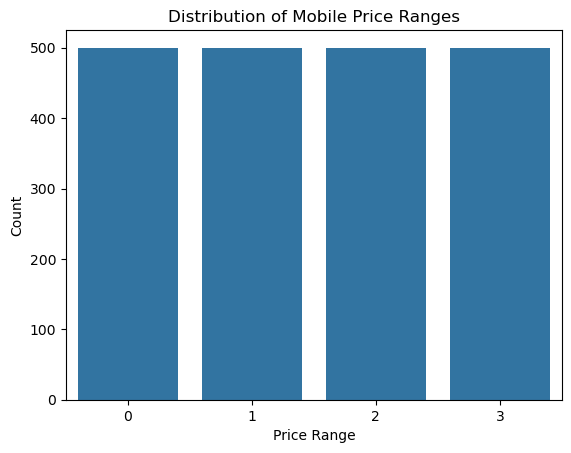

In [88]:
sns.countplot(data=df, x='price_range')
plt.title("Distribution of Mobile Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Count")
plt.show()

Correlation heatmap

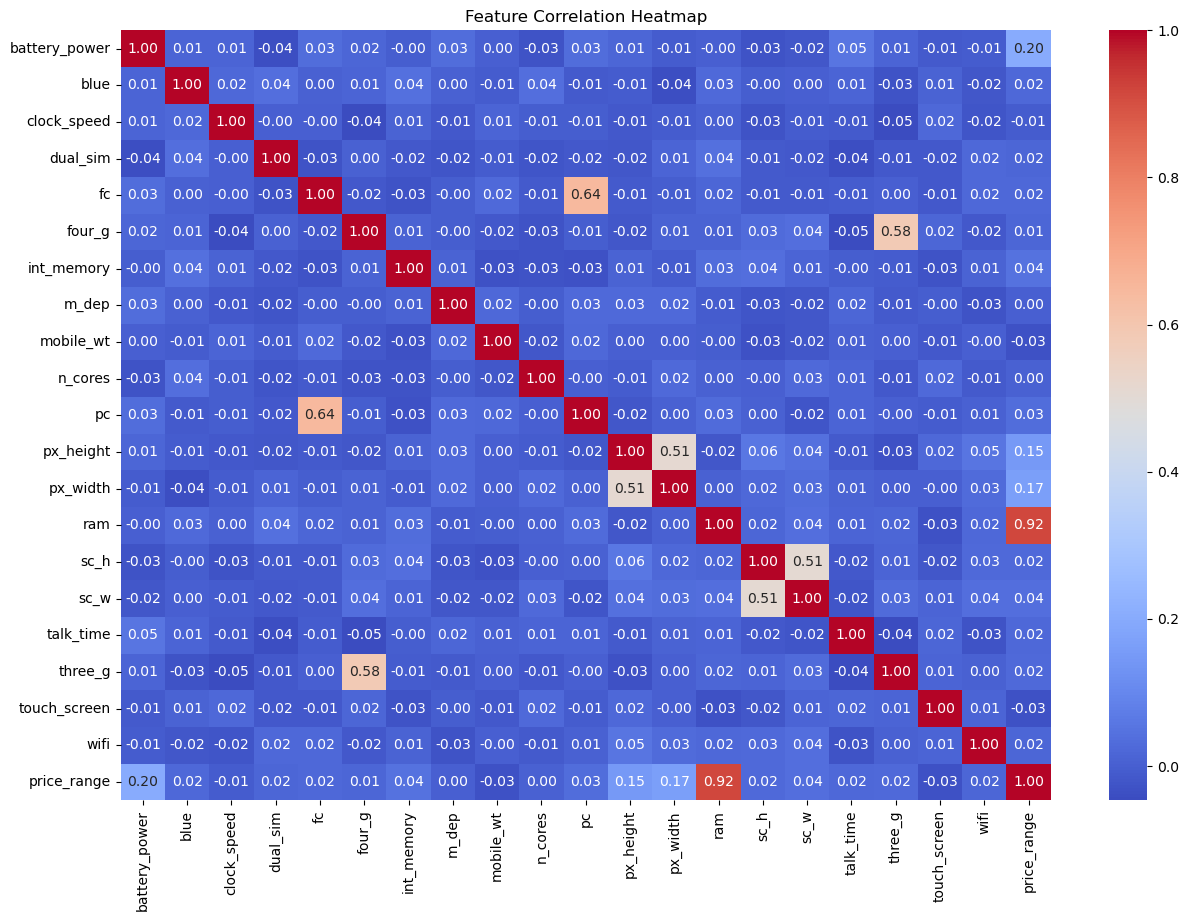

In [89]:
plt.figure(figsize=(15, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

Feature analysis

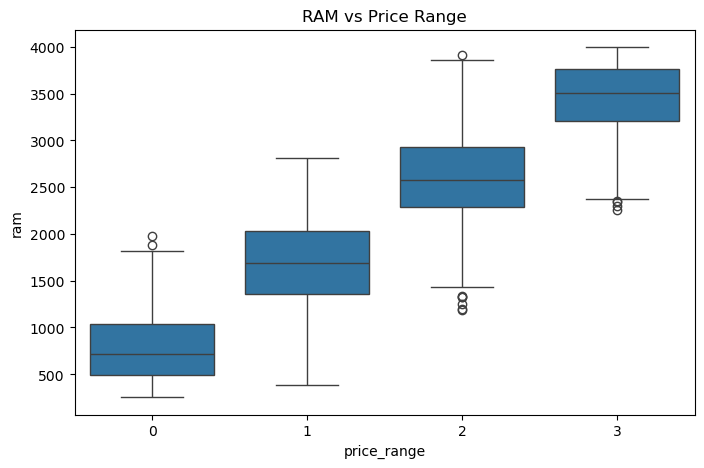

In [90]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='price_range', y='ram')
plt.title("RAM vs Price Range")
plt.show()

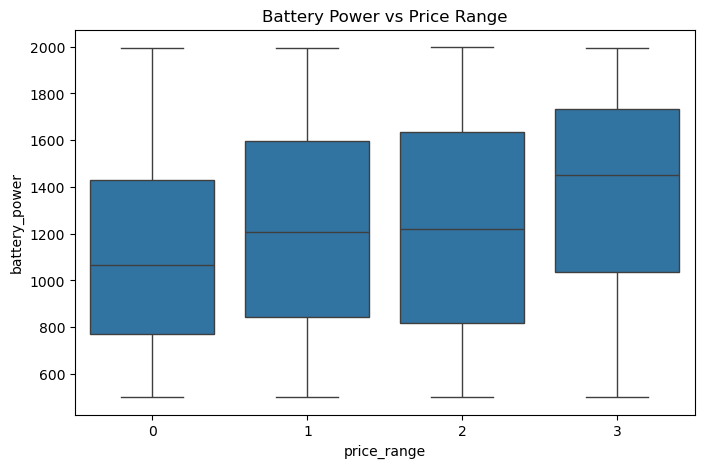

In [91]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='price_range', y='battery_power')
plt.title("Battery Power vs Price Range")
plt.show()

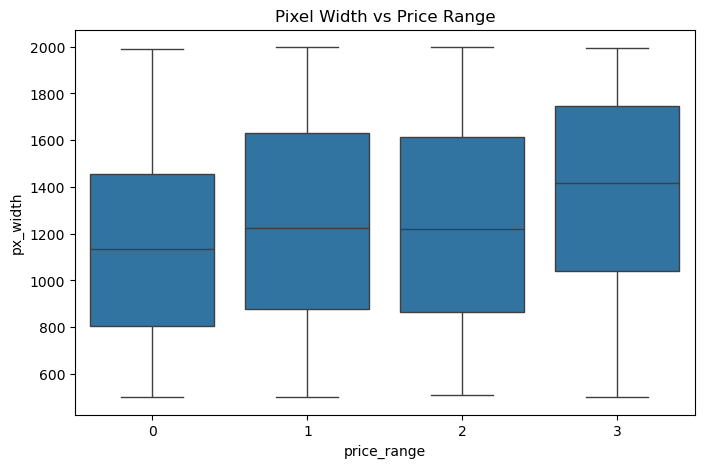

In [92]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='price_range', y='px_width')
plt.title("Pixel Width vs Price Range")
plt.show()

Separate features and target

In [93]:
X = df.drop('price_range', axis=1)
y = df['price_range']

from sklearn.model_selection import train_test_split

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Feature selection
We have selected the 10 features having the strongest correlation with our target.

In [94]:
train_data = X_train_full.copy()
train_data['price_range'] = y_train

correlation = train_data.corr()['price_range'].abs().sort_values(ascending=False)

selected_features = correlation.drop('price_range').head(10).index.tolist()

selected_features

['ram',
 'battery_power',
 'px_width',
 'px_height',
 'int_memory',
 'sc_w',
 'pc',
 'mobile_wt',
 'touch_screen',
 'sc_h']

In [95]:
X_train = X_train_full[selected_features]
X_test = X_test_full[selected_features]

Train-test split

In [96]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1600, 10), (400, 10), (1600,), (400,))

Feature scaling

In [97]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Import ML algorithms

In [98]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

Train Logistic Regression

In [99]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Train KNN

In [100]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

Train Decision Tree

In [101]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

Train Random Forest

In [102]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

Model evaluation

In [103]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (lr_model, lr_predictions),
    "KNN": (knn_model, knn_predictions),
    "Decision Tree": (dt_model, dt_predictions),
    "Random Forest": (rf_model, rf_predictions)
}

results = []

for name, (model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average='weighted'),
        "Recall": recall_score(y_test, predictions, average='weighted'),
        "F1 Score": f1_score(y_test, predictions, average='weighted')
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9800,0.980194,0.9800,0.980049
1,KNN,0.6875,0.690406,0.6875,0.688157
2,Decision Tree,0.8625,0.864422,0.8625,0.862918
3,Random Forest,0.9125,0.912906,0.9125,0.912400


Model comparison graph

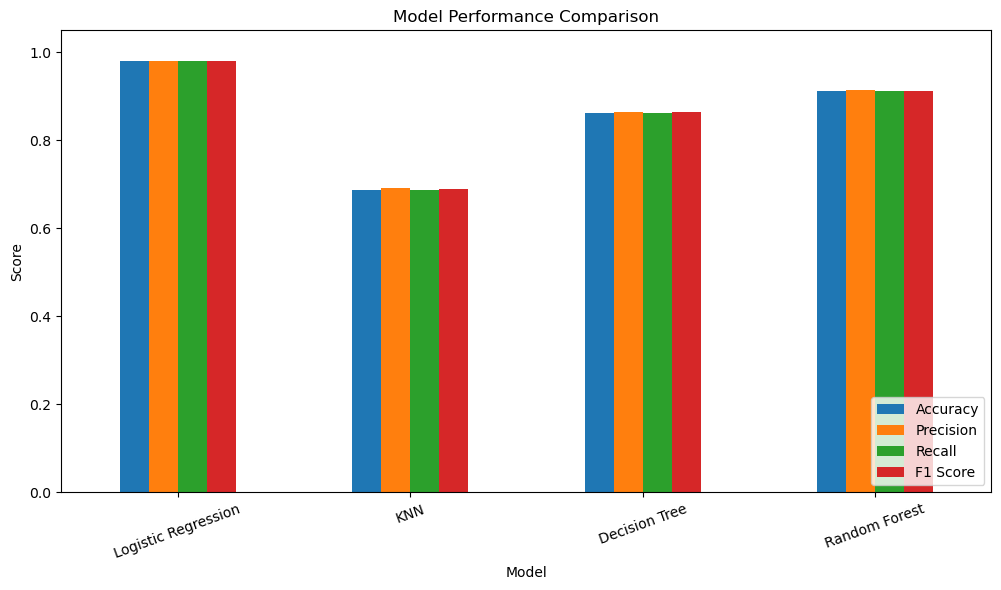

In [104]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar', figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.show()

Best model selection

We have selected the model with the highest weighted F1 score.

In [105]:
best_model_name = results_df.loc[results_df['F1 Score'].idxmax(), 'Model']

best_model_name

'Logistic Regression'

In [106]:
best_model, best_predictions = models[best_model_name]

best_model

LogisticRegression(max_iter=1000)

Classification report

In [107]:
from sklearn.metrics import classification_report

print(classification_report(y_test, best_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       0.98      0.98      0.98       100
           2       0.95      0.97      0.96       100
           3       0.99      0.97      0.98       100

    accuracy                           0.98       400
   macro avg       0.98      0.98      0.98       400
weighted avg       0.98      0.98      0.98       400



Confusion matrix

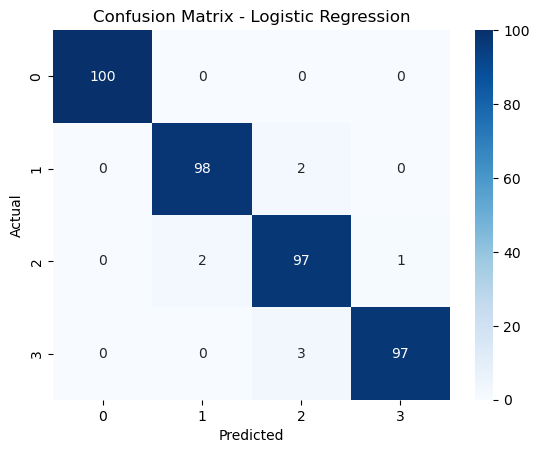

In [108]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Feature importance

In [109]:
if hasattr(best_model, 'feature_importances_'):
    importance = pd.Series(
        best_model.feature_importances_,
        index=selected_features
    ).sort_values(ascending=False)

elif hasattr(best_model, 'coef_'):
    importance = pd.Series(
        np.mean(np.abs(best_model.coef_), axis=0),
        index=selected_features
    ).sort_values(ascending=False)

else:
    importance = None

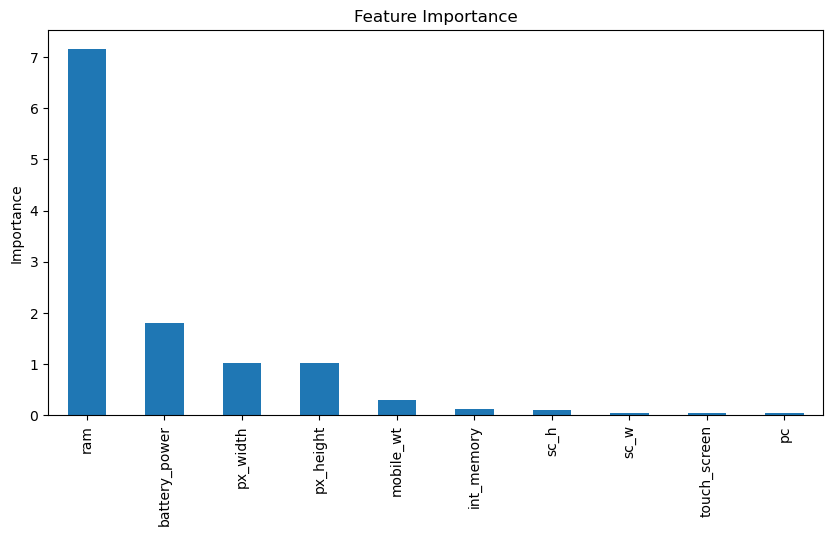

In [110]:
if importance is not None:
    importance.plot(kind='bar', figsize=(10, 5))
    plt.title("Feature Importance")
    plt.ylabel("Importance")
    plt.show()

Save trained model

In [111]:
import joblib

model_bundle = {
    'model': best_model,
    'model_name': best_model_name,
    'selected_features': selected_features,
    'scaler': scaler if best_model_name in ['Logistic Regression', 'KNN'] else None
}

joblib.dump(model_bundle, 'mobile_price_model.pkl')

['mobile_price_model.pkl']